In [10]:
#1. Przygotowanie danych

In [11]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

data = pd.read_csv('VLagun_Crus_Basins.csv') # [cite: 11, 28]
data.dropna(inplace=True)

X = data.iloc[:, :-1]
y = data.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=16)

In [12]:
#2. Budowa i trenowanie modelu

In [13]:
logreg = LogisticRegression(random_state=16)
logreg.fit(X_train, y_train)

y_pred = logreg.predict(X_test)

In [14]:
#3. Ocena modelu (Macierz Pomyłek i Raport)

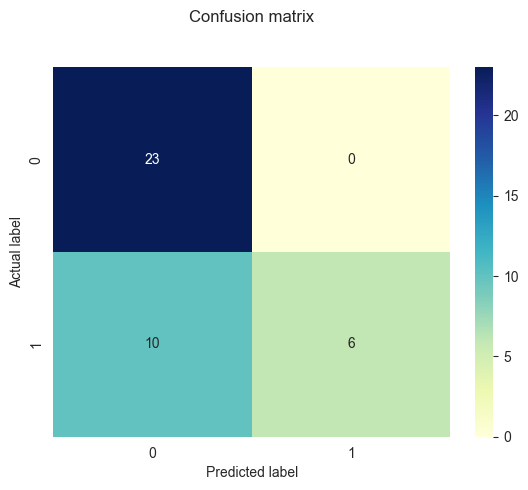

                      precision    recall  f1-score   support

marine influence (0)       0.70      1.00      0.82        23
  land influence (1)       1.00      0.38      0.55        16

            accuracy                           0.74        39
           macro avg       0.85      0.69      0.68        39
        weighted avg       0.82      0.74      0.71        39



In [15]:
cnf_matrix = metrics.confusion_matrix(y_test, y_pred)

sns.heatmap(pd.DataFrame(cnf_matrix), annot=True, cmap="YlGnBu", fmt='g')
plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()

target_names = ['marine influence (0)', 'land influence (1)']
print(metrics.classification_report(y_test, y_pred, target_names=target_names))

In [16]:
#4. Krzywa ROC i AUC

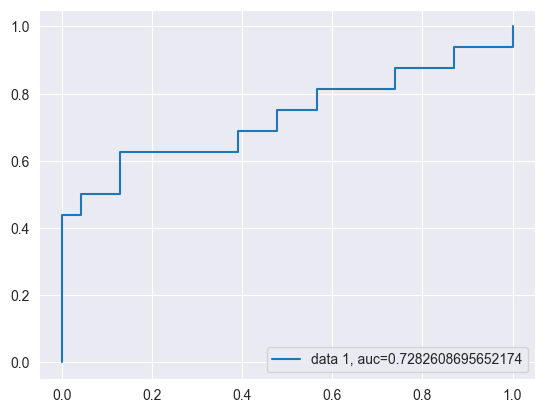

In [17]:
y_pred_proba = logreg.predict_proba(X_test)[::,1]
fpr, tpr, _ = metrics.roc_curve(y_test,  y_pred_proba)
auc = metrics.roc_auc_score(y_test, y_pred_proba)

plt.plot(fpr, tpr, label="data 1, auc="+str(auc))
plt.legend(loc=4)
plt.show()